# 01 — Gaussian primordial potential $\Phi^{\rm G}$

Phase 1 of the JAX GENGARS rewrite. We generate the Gaussian potential from a white-noise field, visualize a 2D slice of the 3D field, and check that the measured 3D power spectrum matches the target $P_\Phi(k)$ and that the implied matter field recovers $P_m(k)$.

Run with the **Python (jaxpng)** kernel.

In [1]:
import numpy as np
import jax, jax.numpy as jnp
import matplotlib.pyplot as plt
import jaxpng  # enables float64
from jaxpng import cosmology as C, gaussian, grids, measure
from jaxpng.config import Box
print('jax', jax.__version__, jax.devices())

Matplotlib is building the font cache; this may take a moment.


jax 0.10.1 [CpuDevice(id=0)]


In [2]:
TK = '../../gengars/inputs/planck18_transfer.dat'
cosmo = C.make_cosmo(TK, omega_m=0.3175, omega_l=0.6825, omega_b=0.049,
                     hubble=0.6711, n_s=0.9624, sigma8=0.834, sigma8_norm=True)
box = Box(N=128, L=1000.0)
print('N=%d  L=%g  dk=%.4f  kNy=%.3f  D(1)=%.4f' % (box.N, box.L, box.dk, box.kny, float(C.growth_D(cosmo,1.0))))

N=128  L=1000  dk=0.0063  kNy=0.402  D(1)=0.7892


## Generate $\Phi^{\rm G}$ from white noise

In [3]:
key = jax.random.PRNGKey(42)
w = jax.random.normal(key, box.rshape)
phi_k = gaussian.phiG_from_white_noise(w, cosmo, box)   # (N,N,N//2+1) k-space
phi_x = jnp.fft.irfftn(phi_k, s=box.rshape)             # real-space field
print('Phi^G real-space std =', float(jnp.std(phi_x)), ' DC =', abs(complex(phi_k[0,0,0])))

Phi^G real-space std = 6.100910337377316e-05  DC = 0.0


## Visualize the field (2D slices of the 3D box)

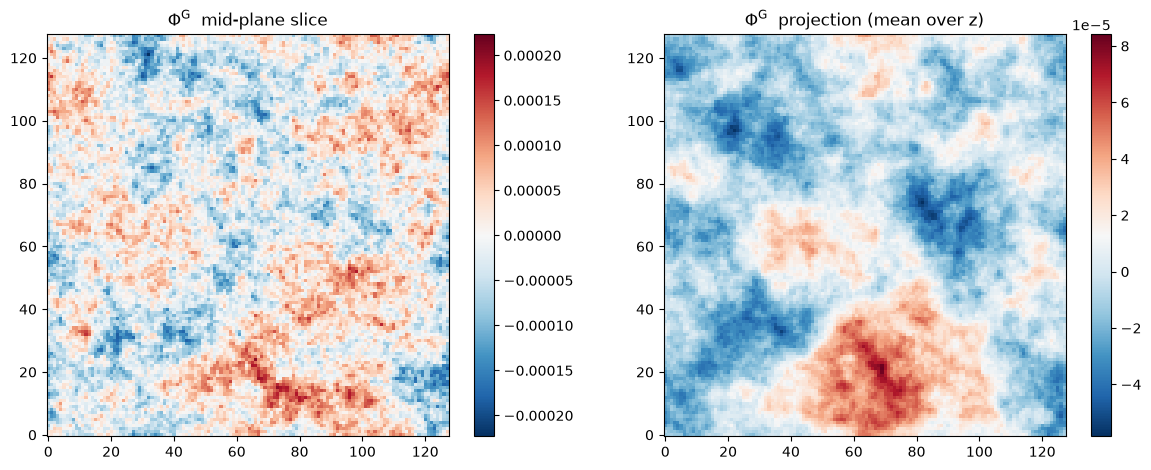

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
sl = np.asarray(phi_x[box.N//2])
v = np.max(np.abs(sl))
im0 = ax[0].imshow(sl, origin='lower', cmap='RdBu_r', vmin=-v, vmax=v)
ax[0].set_title('$\\Phi^{\\rm G}$  mid-plane slice'); plt.colorbar(im0, ax=ax[0], fraction=0.046)
proj = np.asarray(jnp.mean(phi_x, axis=0))
im1 = ax[1].imshow(proj, origin='lower', cmap='RdBu_r')
ax[1].set_title('$\\Phi^{\\rm G}$  projection (mean over z)'); plt.colorbar(im1, ax=ax[1], fraction=0.046)
plt.tight_layout(); plt.show()

## Power spectrum check: measured $P_\Phi(k)$ vs target
Average over several realizations (via `vmap`) and compare to `cosmology.power_phi`.

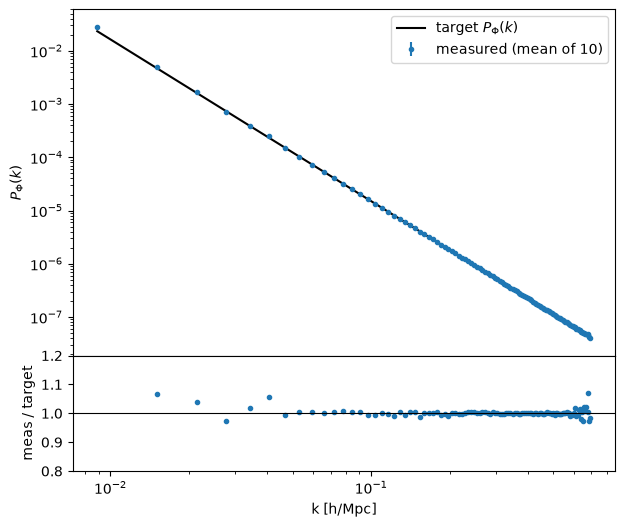

median meas/target over well-sampled band = 1.0021825868358138


In [5]:
nreal = 10
keys = jax.random.split(jax.random.PRNGKey(0), nreal)
def measure_phiG(key):
    ww = jax.random.normal(key, box.rshape)
    return measure.power_spectrum(gaussian.phiG_from_white_noise(ww, cosmo, box), box.L)
ks, Pks = jax.vmap(measure_phiG)(keys)
k = np.asarray(ks[0]); Pmean = np.asarray(jnp.mean(Pks, 0)); Pstd = np.asarray(jnp.std(Pks, 0))
Ptar = np.asarray(C.power_phi(cosmo, jnp.asarray(k)))
fig, (a0, a1) = plt.subplots(2, 1, figsize=(7, 6), sharex=True,
                             gridspec_kw=dict(height_ratios=[3, 1], hspace=0))
a0.loglog(k, Ptar, 'k-', label='target $P_\\Phi(k)$')
a0.errorbar(k, Pmean, yerr=Pstd/np.sqrt(nreal), fmt='C0.', label='measured (mean of %d)' % nreal)
a0.set_ylabel('$P_\\Phi(k)$'); a0.legend()
a1.semilogx(k, Pmean/Ptar, 'C0.'); a1.axhline(1, color='k', lw=0.8)
a1.set_ylim(0.8, 1.2); a1.set_ylabel('meas / target'); a1.set_xlabel('k [h/Mpc]')
plt.show()
band = (k > 2*box.dk) & (k < 0.3)
print('median meas/target over well-sampled band =', float(np.median((Pmean/Ptar)[band])))

## Consistency: implied matter field recovers $P_m(k)$
$\delta(k) = M(k)\,\Phi^{\rm G}(k)$ should have the linear matter power spectrum.

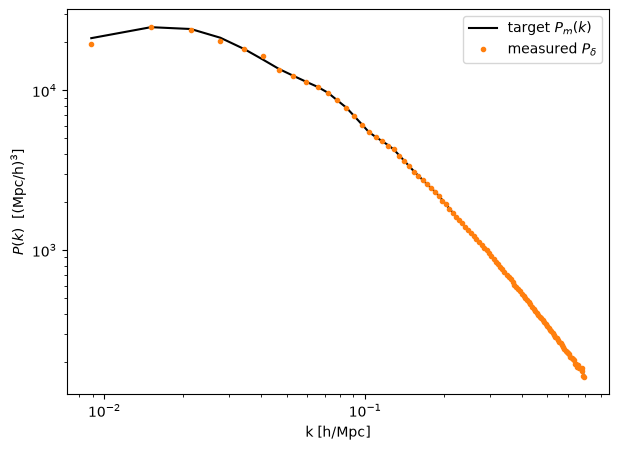

In [6]:
_, _, _, kmag = grids.k_grid(box)
M = C.poisson_M(cosmo, kmag)
def measure_delta(key):
    ww = jax.random.normal(key, box.rshape)
    pk = gaussian.phiG_from_white_noise(ww, cosmo, box)
    return measure.power_spectrum(pk * M, box.L)
kk, Pds = jax.vmap(measure_delta)(keys)
kk = np.asarray(kk[0]); Pdm = np.asarray(jnp.mean(Pds, 0))
plt.figure(figsize=(7, 5))
plt.loglog(kk, np.asarray(C.Pk_matter(cosmo, jnp.asarray(kk))), 'k-', label='target $P_m(k)$')
plt.loglog(kk, Pdm, 'C1.', label='measured $P_\\delta$')
plt.xlabel('k [h/Mpc]'); plt.ylabel('$P(k)$  [(Mpc/h)$^3$]'); plt.legend(); plt.show()

**Phase 1 OK** when the ratio panel sits at 1 across well-sampled scales. Next: Phase 2 — local PNG $\Phi^{\rm NG}$ via the Schwinger integral, anchored to $\Phi^{\rm NG}(x)=\Phi^{\rm G}(x)^2-\langle\Phi^{\rm G2}\rangle$.